# Exploratory Data Analysis (EDA) on Weather Data
Google Colab notebook: create messy data, clean it, then explore it with 5 visualizations.

Run the cells from top to bottom (Runtime > Run all).

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 2. Create the messy (raw) weather dataset
30 daily records with some missing values. Skip this section if you upload your own file.

In [2]:
rng = np.random.default_rng(42)   # fixed seed -> same data every run
n = 30

cloud = np.clip(rng.normal(55, 25, n), 5, 100).round(0)
humid = np.clip(40 + 0.45 * cloud + rng.normal(0, 8, n), 25, 98).round(0)
temp  = np.clip(34 - 0.12 * humid + rng.normal(0, 2.2, n), 18, 38).round(1)
press = np.clip(1016 - 0.09 * cloud + rng.normal(0, 3.0, n), 1000, 1024).round(1)
rain  = np.where(humid > 72, np.clip((humid - 68) * rng.uniform(0.6, 1.8, n), 0, 60), 0).round(1)
wind  = np.clip(8 + 0.10 * rain + rng.normal(6, 4, n), 2, 45).round(1)
vis   = np.clip(11 - 0.05 * humid - 0.08 * rain + rng.normal(2.5, 1, n), 1.5, 12).round(1)

def weather_code(c, r, w):
    if r >= 25 and w >= 18: return 3   # Stormy
    if r > 0:               return 2   # Rainy
    if c >= 50:             return 1   # Cloudy
    return 0                           # Sunny

labels = {0: "Sunny", 1: "Cloudy", 2: "Rainy", 3: "Stormy"}
codes = [weather_code(c, r, w) for c, r, w in zip(cloud, rain, wind)]

raw = pd.DataFrame({
    "Temperature": temp, "Humidity": humid, "Pressure": press,
    "Wind_Speed": wind, "Rainfall": rain, "Cloud_Cover": cloud,
    "Visibility": vis, "Weather_Type": [labels[c] for c in codes],
})

# make it messy: blank out some readings
raw.loc[[4, 17], "Temperature"] = np.nan
raw.loc[[9, 22], "Humidity"]    = np.nan
raw.loc[[13],    "Wind_Speed"]  = np.nan
raw.loc[[6, 25], "Visibility"]  = np.nan

raw.to_excel("messy_weather_data.xlsx", index=False)
raw.head()

,Temperature,Humidity,Pressure,Wind_Speed,Rainfall,Cloud_Cover,Visibility,Weather_Type
0,20.1,85.0,1012.3,14.6,11.9,63.0,9.6,Rainy
1,27.3,50.0,1013.1,9.9,0.0,29.0,11.2,Sunny
2,26.1,69.0,1008.1,7.3,0.0,74.0,9.6,Cloudy
3,27.0,69.0,1008.7,12.1,0.0,79.0,11.2,Cloudy
4,NaN,48.0,1010.4,13.8,0.0,6.0,11.5,Sunny


**Using your own data instead?** Upload your file in the Colab Files panel and run:
```python
raw = pd.read_excel('your_file.xlsx')   # or pd.read_csv('your_file.csv')
```

## 3. Inspect the messy data

In [3]:
messy = pd.read_excel("messy_weather_data.xlsx")
print("Shape:", messy.shape)
print("\nData types:\n", messy.dtypes)
print("\nMissing values per column:\n", messy.isna().sum())
print("\nDuplicate rows:", messy.duplicated().sum())
messy.info()

Shape: (30, 8)

Data types:
 Temperature     float64
Humidity        float64
Pressure        float64
Wind_Speed      float64
Rainfall        float64
Cloud_Cover       int64
Visibility      float64
Weather_Type     object
dtype: object

Missing values per column:
 Temperature     2
Humidity        2
Pressure        0
Wind_Speed      1
Rainfall        0
Cloud_Cover     0
Visibility      2
Weather_Type    0
dtype: int64

Duplicate rows: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Temperature   28 non-null     float64
 1   Humidity      28 non-null     float64
 2   Pressure      30 non-null     float64
 3   Wind_Speed    29 non-null     float64
 4   Rainfall      30 non-null     float64
 5   Cloud_Cover   30 non-null     int64  
 6   Visibility    28 non-null     float64
 7   Weather_Type  30 non-null     object 
dtypes: float64(6), int64(1)

## 4. Clean the data
- Fill missing numeric values with the column median
- Encode `Weather_Type`: Sunny = 0, Cloudy = 1, Rainy = 2

In [4]:
cleaned = messy.copy()

for col in ["Temperature", "Humidity", "Wind_Speed", "Visibility"]:
    cleaned[col] = cleaned[col].fillna(cleaned[col].median())

mapping = {"Sunny": 0, "Cloudy": 1, "Rainy": 2, "Stormy": 3}
cleaned["Weather_Type"] = cleaned["Weather_Type"].map(mapping).astype(int)

print("Missing values after cleaning:", int(cleaned.isna().sum().sum()))
cleaned.to_excel("cleaned_weather_data.xlsx", index=False)
cleaned.head()

Missing values after cleaning: 0


,Temperature,Humidity,Pressure,Wind_Speed,Rainfall,Cloud_Cover,Visibility,Weather_Type
0,20.10,85.0,1012.3,14.6,11.9,63,9.6,2
1,27.30,50.0,1013.1,9.9,0.0,29,11.2,0
2,26.10,69.0,1008.1,7.3,0.0,74,9.6,1
3,27.00,69.0,1008.7,12.1,0.0,79,11.2,1
4,25.75,48.0,1010.4,13.8,0.0,6,11.5,0


## 5. Descriptive statistics

In [5]:
clean = pd.read_excel("cleaned_weather_data.xlsx")
print("Shape:", clean.shape)
clean.describe().T.round(2)

Shape: (30, 8)


,count,mean,std,min,25%,50%,75%,max
Temperature,30.0,25.68,2.01,20.1,24.88,25.75,26.88,28.9
Humidity,30.0,65.90,10.03,48.0,58.25,65.00,74.75,85.0
Pressure,30.0,1010.20,2.38,1006.0,1008.25,1010.30,1012.28,1015.0
Wind_Speed,30.0,14.05,3.73,7.3,11.85,13.80,15.73,22.5
Rainfall,30.0,3.19,5.63,0.0,0.00,0.00,5.18,16.9
Cloud_Cover,30.0,55.43,19.48,6.0,44.50,57.50,67.75,86.0
Visibility,30.0,9.94,1.14,7.6,9.33,9.80,10.58,12.0
Weather_Type,30.0,0.93,0.78,0.0,0.00,1.00,1.75,2.0


## 6. Visualizations

### Figure 1: Temperature distribution

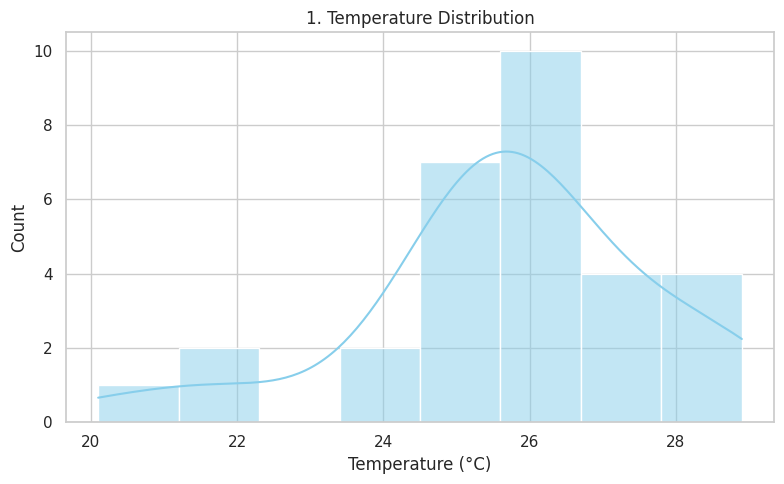

In [6]:
plt.figure(figsize=(8, 5))
sns.histplot(clean["Temperature"], bins=8, kde=True, color="skyblue")
plt.title("1. Temperature Distribution")
plt.xlabel("Temperature (°C)"); plt.ylabel("Count")
plt.tight_layout(); plt.show()

### Figure 2: Average temperature and humidity by weather type

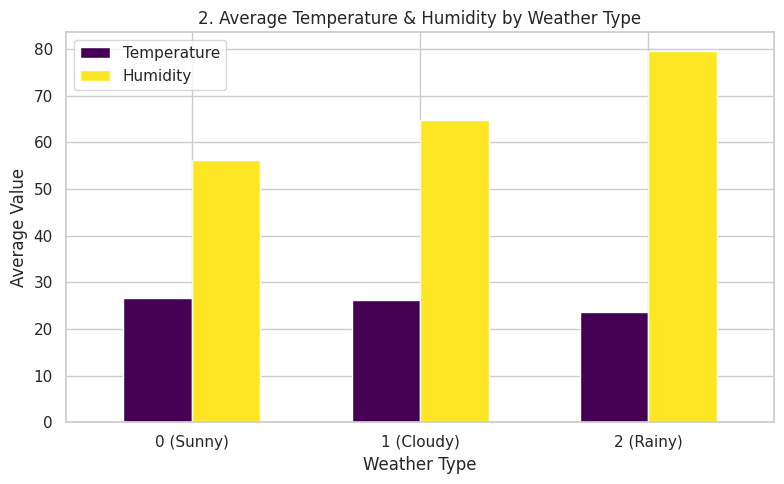

In [7]:
avg = clean.groupby("Weather_Type")[["Temperature", "Humidity"]].mean()
ax = avg.plot(kind="bar", figsize=(8, 5), colormap="viridis", width=0.6)
names = {0: "Sunny", 1: "Cloudy", 2: "Rainy", 3: "Stormy"}
ax.set_xticklabels([f"{k} ({names[k]})" for k in avg.index], rotation=0)
plt.title("2. Average Temperature & Humidity by Weather Type")
plt.xlabel("Weather Type"); plt.ylabel("Average Value")
plt.tight_layout(); plt.show()

### Figure 3: Humidity vs temperature

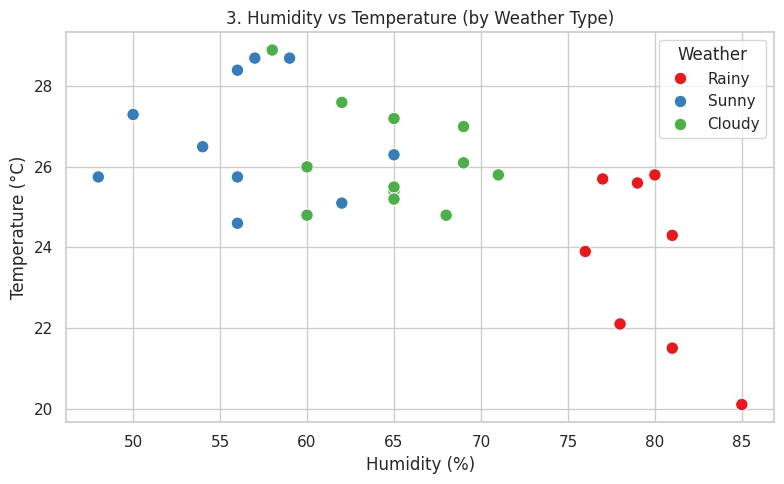

In [8]:
plt.figure(figsize=(8, 5))
plot_df = clean.assign(Weather=clean["Weather_Type"].map(names))
sns.scatterplot(data=plot_df, x="Humidity", y="Temperature", hue="Weather", palette="Set1", s=80)
plt.title("3. Humidity vs Temperature (by Weather Type)")
plt.xlabel("Humidity (%)"); plt.ylabel("Temperature (°C)")
plt.tight_layout(); plt.show()

### Figure 4: Weather type across pressure groups

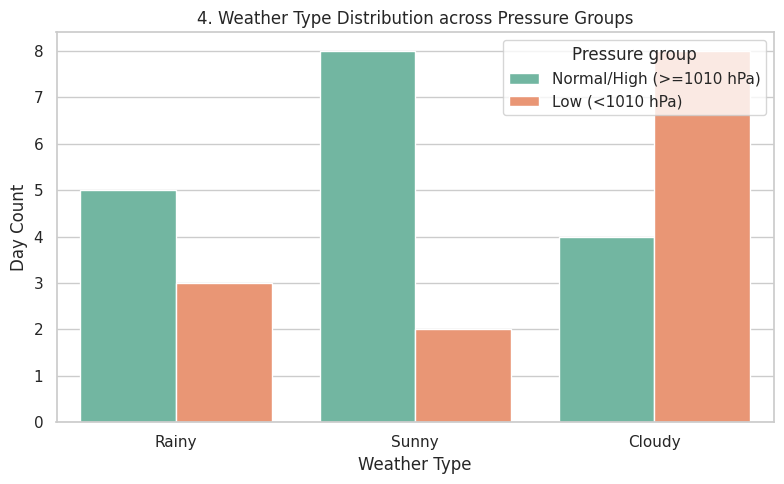

In [9]:
clean["Pressure_Group"] = np.where(clean["Pressure"] < 1010,
                                   "Low (<1010 hPa)", "Normal/High (>=1010 hPa)")
plt.figure(figsize=(8, 5))
sns.countplot(data=clean.assign(Weather=clean["Weather_Type"].map(names)),
              x="Weather", hue="Pressure_Group", palette="Set2")
plt.title("4. Weather Type Distribution across Pressure Groups")
plt.xlabel("Weather Type"); plt.ylabel("Day Count")
plt.legend(title="Pressure group")
plt.tight_layout(); plt.show()

### Figure 5: Correlation heatmap

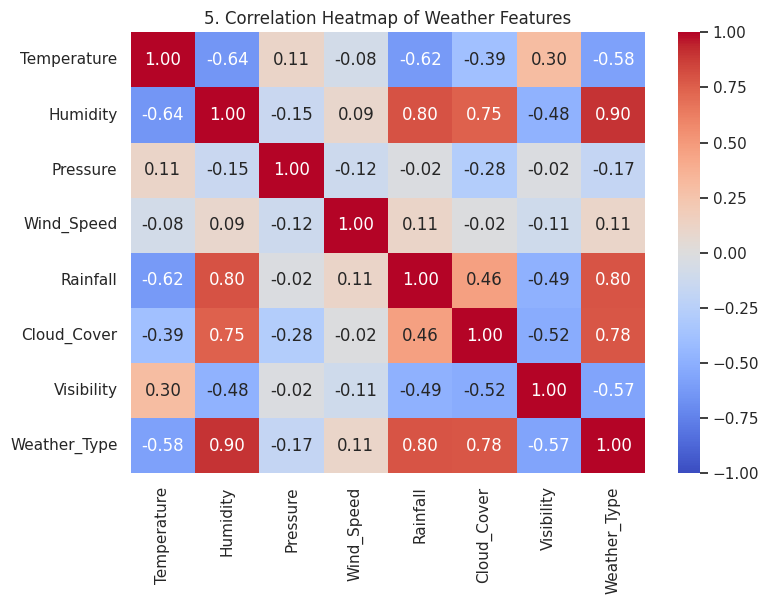

In [10]:
plt.figure(figsize=(8, 6.2))
sns.heatmap(clean.drop(columns=["Pressure_Group"]).corr(),
            annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("5. Correlation Heatmap of Weather Features")
plt.tight_layout(); plt.show()

## 7. Download the files (Colab only)

In [11]:
from google.colab import files
files.download("messy_weather_data.xlsx")
files.download("cleaned_weather_data.xlsx")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>